# 04 — Aprendizaje no supervisado: PCA

**Escenario 4:** Efectividad de campañas de marketing
**Dataset:** `data/processed/bank_scaled.csv` (generado en el notebook 02, ya estandarizado y sin la variable `y`)

**Objetivo:** reducir la cantidad de variables de clientes y campañas, encontrar los componentes principales y ver cuánta información (varianza) explica cada uno.

**Importante:** PCA es una técnica de **reducción de dimensionalidad**, no de agrupamiento. No forma grupos ni clusters. Además, por ser no supervisado, **no usa la variable `y`** para aprender. `y` solo se usa al final para interpretar los resultados.

## 1. Fundamento teórico

### Idea general

Después del preprocesamiento el dataset tiene 41 variables, y en el EDA se vio que varias están muy correlacionadas (por ejemplo `emp.var.rate`, `euribor3m` y `nr.employed`). Esto quiere decir que hay información repetida.

PCA (*Principal Component Analysis*, Análisis de Componentes Principales) crea **nuevas variables**, llamadas componentes principales, que:

- son combinaciones lineales de las variables originales,
- **no están correlacionadas** entre sí,
- están ordenadas de mayor a menor varianza (el primer componente es el que más información guarda).

### Pasos matemáticos

**1. Estandarizar los datos** (ya se hizo en el notebook 02), para que todas las variables tengan media 0 y varianza 1:

$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$

**2. Calcular la matriz de covarianza** de los datos estandarizados $Z$ (con $n$ registros):

$$\Sigma = \frac{1}{n-1} Z^{T} Z$$

**3. Obtener los autovalores y autovectores** de $\Sigma$:

$$\Sigma \, v_k = \lambda_k \, v_k$$

- Cada **autovector** $v_k$ indica la dirección del componente $k$ (qué peso tiene cada variable original). A estos pesos se les llama **cargas** o *loadings*.
- Cada **autovalor** $\lambda_k$ indica cuánta varianza captura ese componente.

**4. Proyectar los datos** sobre los $k$ primeros autovectores:

$$PC_k = Z \, v_k$$

**5. Varianza explicada** por cada componente:

$$\text{Varianza explicada}_k = \frac{\lambda_k}{\sum_{j=1}^{p} \lambda_j}$$

### Función objetivo

El primer componente es la dirección que **maximiza la varianza** de los datos proyectados:

$$v_1 = \arg\max_{\|v\|=1} \; v^{T} \Sigma \, v$$

Los siguientes componentes hacen lo mismo, pero con la condición de ser perpendiculares (ortogonales) a los anteriores.

### ¿Cómo elegir el número de componentes?

Se usan tres criterios comunes:

- **Varianza acumulada:** quedarse con los componentes necesarios para explicar un porcentaje alto de la varianza (por ejemplo 80% o 90%).
- **Criterio de Kaiser:** quedarse con los componentes cuyo autovalor sea mayor a 1 (es decir, que expliquen más que una variable original).
- **Gráfico de sedimentación (*scree plot*):** buscar el "codo" donde la varianza deja de bajar rápido.

## 2. Librerías y carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42

X = pd.read_csv("../data/processed/bank_scaled.csv")
print("Tamaño:", X.shape)
print("¿Contiene la variable y?", "y" in X.columns)
print(f"Media promedio: {X.mean().mean():.4f} | Desviación promedio: {X.std().mean():.4f}")

Tamaño: (41176, 41)
¿Contiene la variable y? False
Media promedio: -0.0000 | Desviación promedio: 1.0000


Se confirma que los datos están estandarizados (media ≈ 0 y desviación ≈ 1) y que no incluyen la variable objetivo.

## 3. Aplicar PCA con todos los componentes

Primero se calculan los 41 componentes posibles para analizar cuánta varianza explica cada uno, y después se decide con cuántos quedarse.

In [2]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X)

autovalores = pca_full.explained_variance_
var_exp = pca_full.explained_variance_ratio_
var_acum = np.cumsum(var_exp)

tabla_var = pd.DataFrame({
    "componente": [f"PC{i+1}" for i in range(len(var_exp))],
    "autovalor": autovalores.round(3),
    "varianza_%": (var_exp * 100).round(2),
    "acumulada_%": (var_acum * 100).round(2),
})
tabla_var.head(20)

,componente,autovalor,varianza_%,acumulada_%
0,PC1,5.252,12.81,12.81
1,PC2,2.444,5.96,18.77
2,PC3,2.207,5.38,24.15
3,PC4,2.121,5.17,29.33
4,PC5,1.708,4.16,33.49
5,PC6,1.483,3.62,37.11
6,PC7,1.367,3.33,40.44
7,PC8,1.263,3.08,43.53
8,PC9,1.260,3.07,46.60
9,PC10,1.247,3.04,49.64


## 4. Varianza explicada

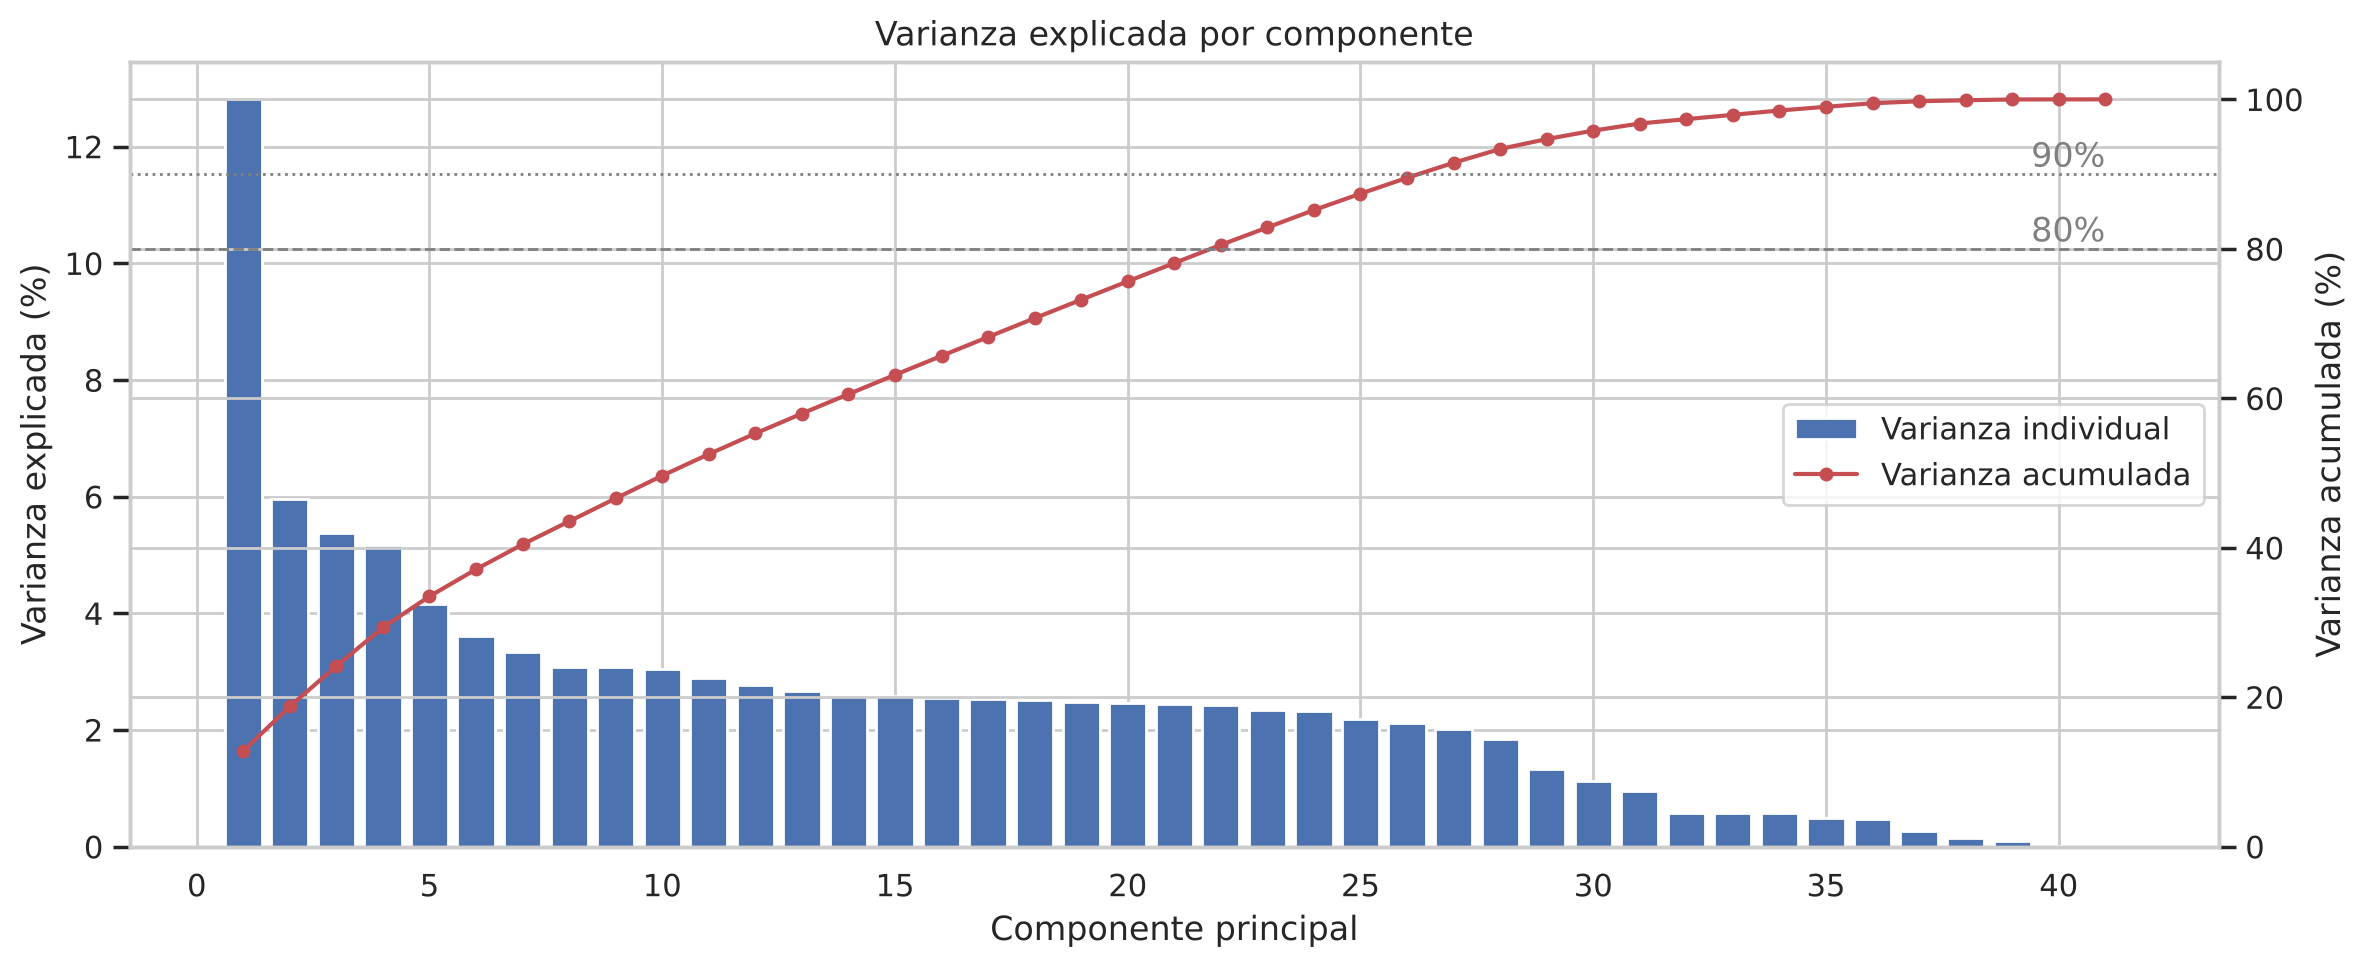

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))
n = len(var_exp)
ax.bar(range(1, n + 1), var_exp * 100, color="#4C72B0", label="Varianza individual")
ax2 = ax.twinx()
ax2.plot(range(1, n + 1), var_acum * 100, color="#C44E52", marker="o", ms=4, label="Varianza acumulada")
ax2.axhline(80, ls="--", color="gray", lw=1)
ax2.axhline(90, ls=":", color="gray", lw=1)
ax2.text(n, 81, "80%", ha="right", color="gray")
ax2.text(n, 91, "90%", ha="right", color="gray")
ax.set_xlabel("Componente principal")
ax.set_ylabel("Varianza explicada (%)")
ax2.set_ylabel("Varianza acumulada (%)")
ax2.set_ylim(0, 105)
ax.set_title("Varianza explicada por componente")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right")
plt.tight_layout()
plt.show()

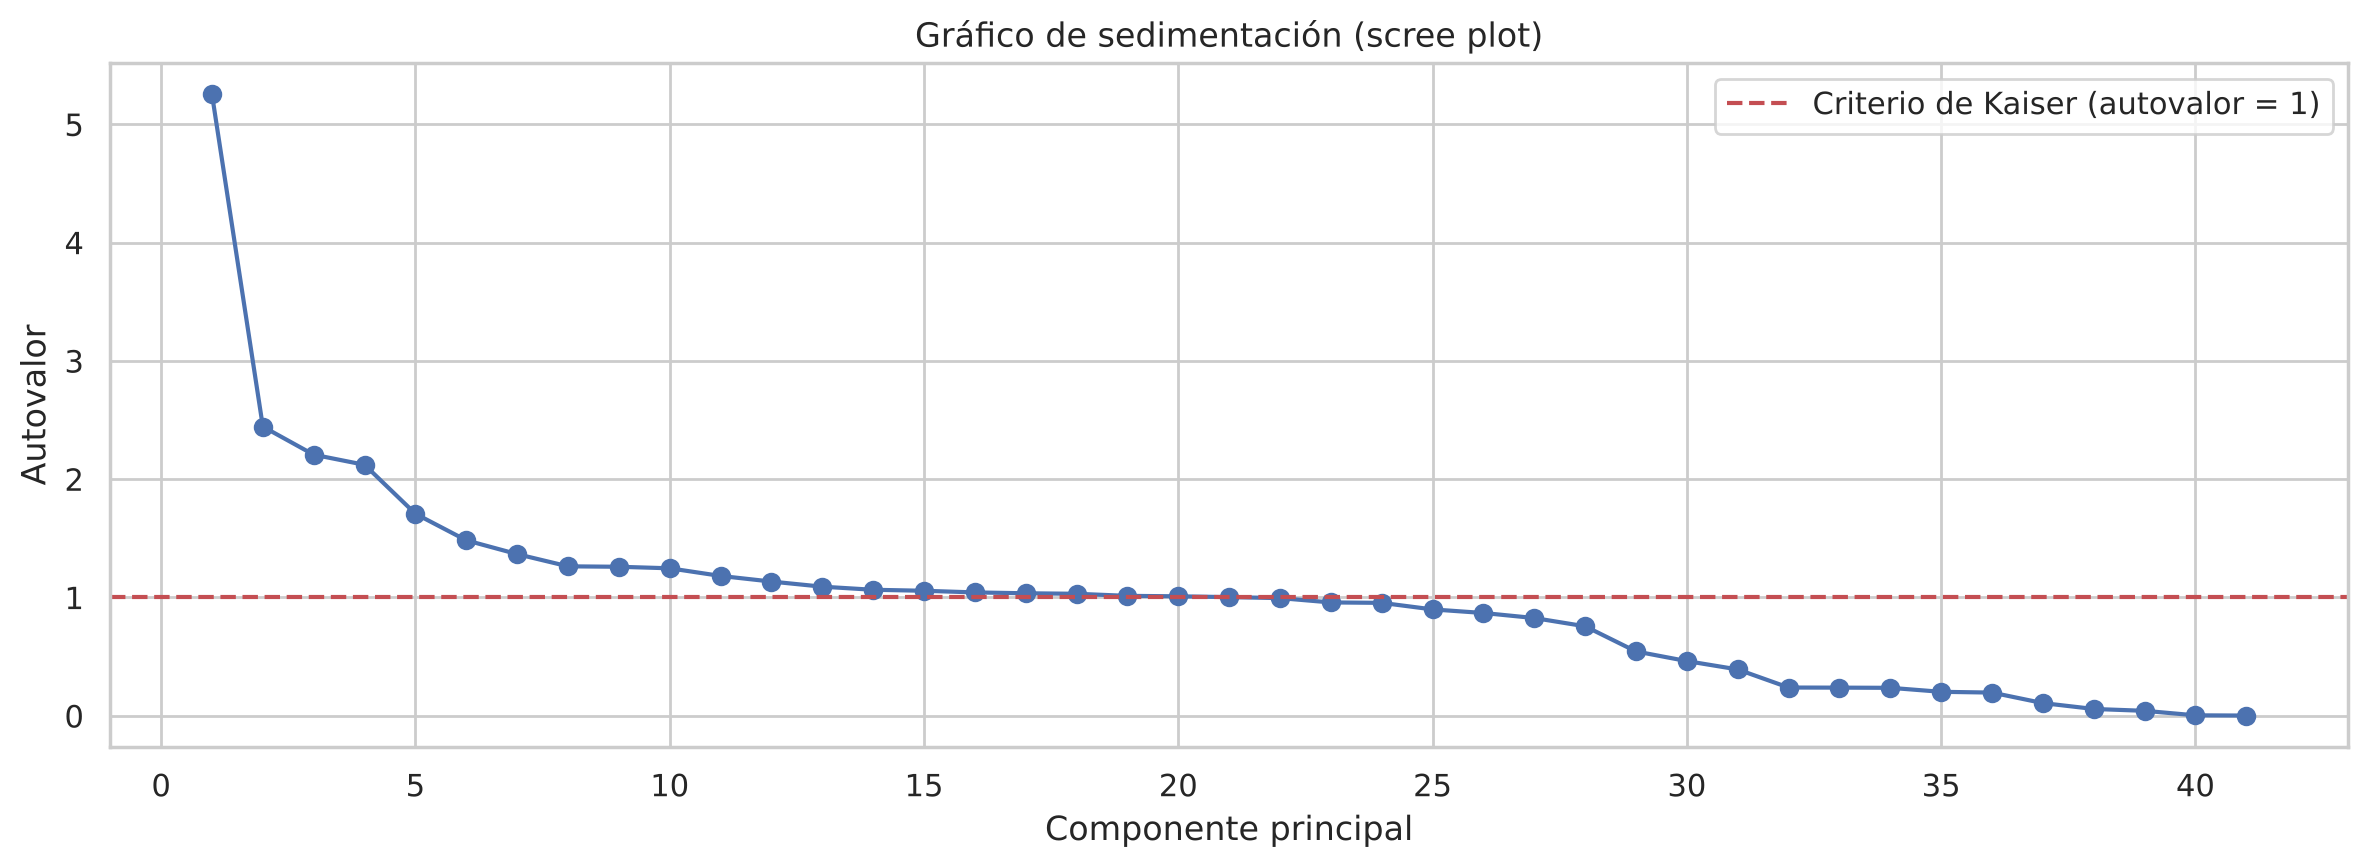

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(range(1, n + 1), autovalores, marker="o", color="#4C72B0")
ax.axhline(1, ls="--", color="#C44E52", label="Criterio de Kaiser (autovalor = 1)")
ax.set_xlabel("Componente principal")
ax.set_ylabel("Autovalor")
ax.set_title("Gráfico de sedimentación (scree plot)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Selección del número de componentes

In [5]:
k_80 = int(np.argmax(var_acum >= 0.80) + 1)
k_90 = int(np.argmax(var_acum >= 0.90) + 1)
k_kaiser = int((autovalores > 1).sum())

print(f"Componentes para explicar el 80% de la varianza: {k_80}")
print(f"Componentes para explicar el 90% de la varianza: {k_90}")
print(f"Componentes con autovalor > 1 (Kaiser):         {k_kaiser}  -> explican {var_acum[k_kaiser-1]*100:.1f}%")

Componentes para explicar el 80% de la varianza: 22
Componentes para explicar el 90% de la varianza: 27
Componentes con autovalor > 1 (Kaiser):         21  -> explican 78.1%


**Decisión:** el criterio de Kaiser da 21 componentes (78,1% de la varianza) y para llegar al 80% se necesitan 22. Como son casi iguales, se eligen **22 componentes**, que conservan un poco más del 80% de la información y reducen el dataset de 41 a 22 variables.

En el scree plot no aparece un "codo" claro: después de PC1 la varianza baja de forma muy gradual. Esto pasa porque muchas variables son binarias del One-Hot Encoding (meses, trabajos, días), que casi no están correlacionadas entre sí, y por eso cada una aporta información propia que es difícil de resumir.

In [6]:
K = k_80
pca = PCA(n_components=K, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print(f"Dimensiones originales: {X.shape[1]} variables")
print(f"Dimensiones reducidas:  {X_pca.shape[1]} componentes")
print(f"Varianza conservada:    {pca.explained_variance_ratio_.sum()*100:.2f}%")
print(f"Reducción:              {(1 - K / X.shape[1]) * 100:.1f}% menos variables")

Dimensiones originales: 41 variables
Dimensiones reducidas:  22 componentes
Varianza conservada:    80.52%
Reducción:              46.3% menos variables


In [7]:
# Verificación: los componentes no están correlacionados entre sí
corr_pcs = np.corrcoef(X_pca, rowvar=False)
fuera_diag = corr_pcs[~np.eye(K, dtype=bool)]
print(f"Correlación máxima entre componentes: {np.abs(fuera_diag).max():.6f}")

Correlación máxima entre componentes: 0.000000


## 6. Cargas (loadings): qué representa cada componente

Las cargas indican cuánto pesa cada variable original en cada componente. Un valor cercano a +1 o −1 significa que esa variable influye mucho en el componente, y el signo indica la dirección.

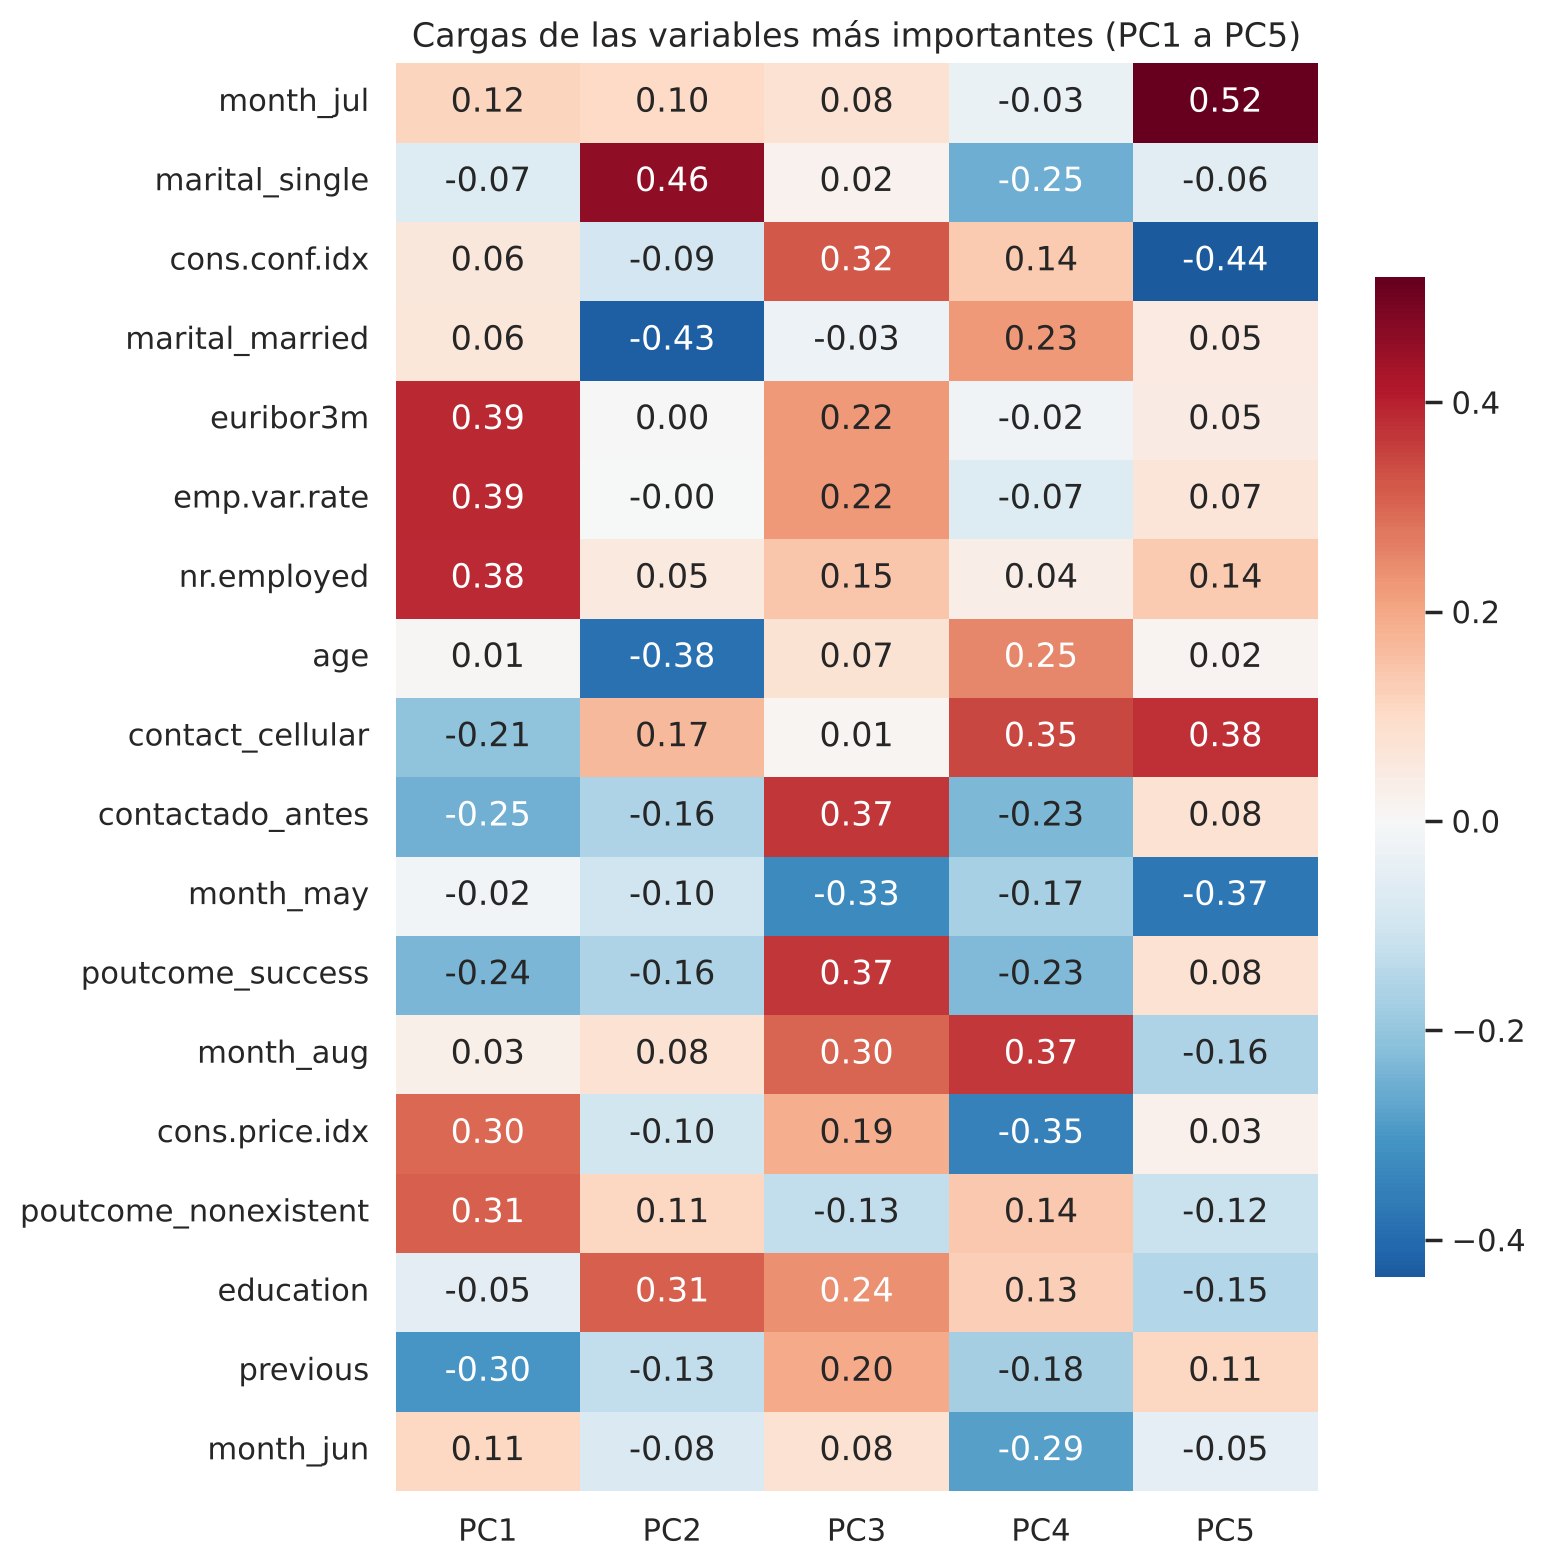

In [8]:
cargas = pd.DataFrame(pca.components_.T, index=X.columns,
                      columns=[f"PC{i+1}" for i in range(K)])

top_vars = cargas.iloc[:, :5].abs().max(axis=1).sort_values(ascending=False).head(18).index
fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(cargas.loc[top_vars, ["PC1", "PC2", "PC3", "PC4", "PC5"]], annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Cargas de las variables más importantes (PC1 a PC5)")
plt.tight_layout()
plt.show()

In [9]:
for pc in ["PC1", "PC2", "PC3", "PC4", "PC5"]:
    orden = cargas[pc].abs().sort_values(ascending=False).head(5).index
    detalle = ", ".join(f"{v} ({cargas.loc[v, pc]:+.2f})" for v in orden)
    print(f"{pc} [{pca.explained_variance_ratio_[int(pc[2:])-1]*100:.1f}%]: {detalle}")

PC1 [12.8%]: euribor3m (+0.39), emp.var.rate (+0.39), nr.employed (+0.38), poutcome_nonexistent (+0.31), previous (-0.30)
PC2 [6.0%]: marital_single (+0.46), marital_married (-0.43), age (-0.38), education (+0.31), job_retired (-0.22)
PC3 [5.4%]: contactado_antes (+0.37), poutcome_success (+0.37), month_may (-0.33), cons.conf.idx (+0.32), month_aug (+0.30)
PC4 [5.2%]: month_aug (+0.37), cons.price.idx (-0.35), contact_cellular (+0.35), month_jun (-0.29), age (+0.25)
PC5 [4.2%]: month_jul (+0.52), cons.conf.idx (-0.44), contact_cellular (+0.38), month_may (-0.37), month_nov (+0.19)


## 7. Visualización en 2 dimensiones

Se grafican los clientes usando solo PC1 y PC2. Para que el gráfico se pueda leer se toma una muestra de 5.000 clientes.

Los colores según `y` se agregan **después** de calcular PCA, solo para interpretar. El modelo nunca vio la variable `y`.

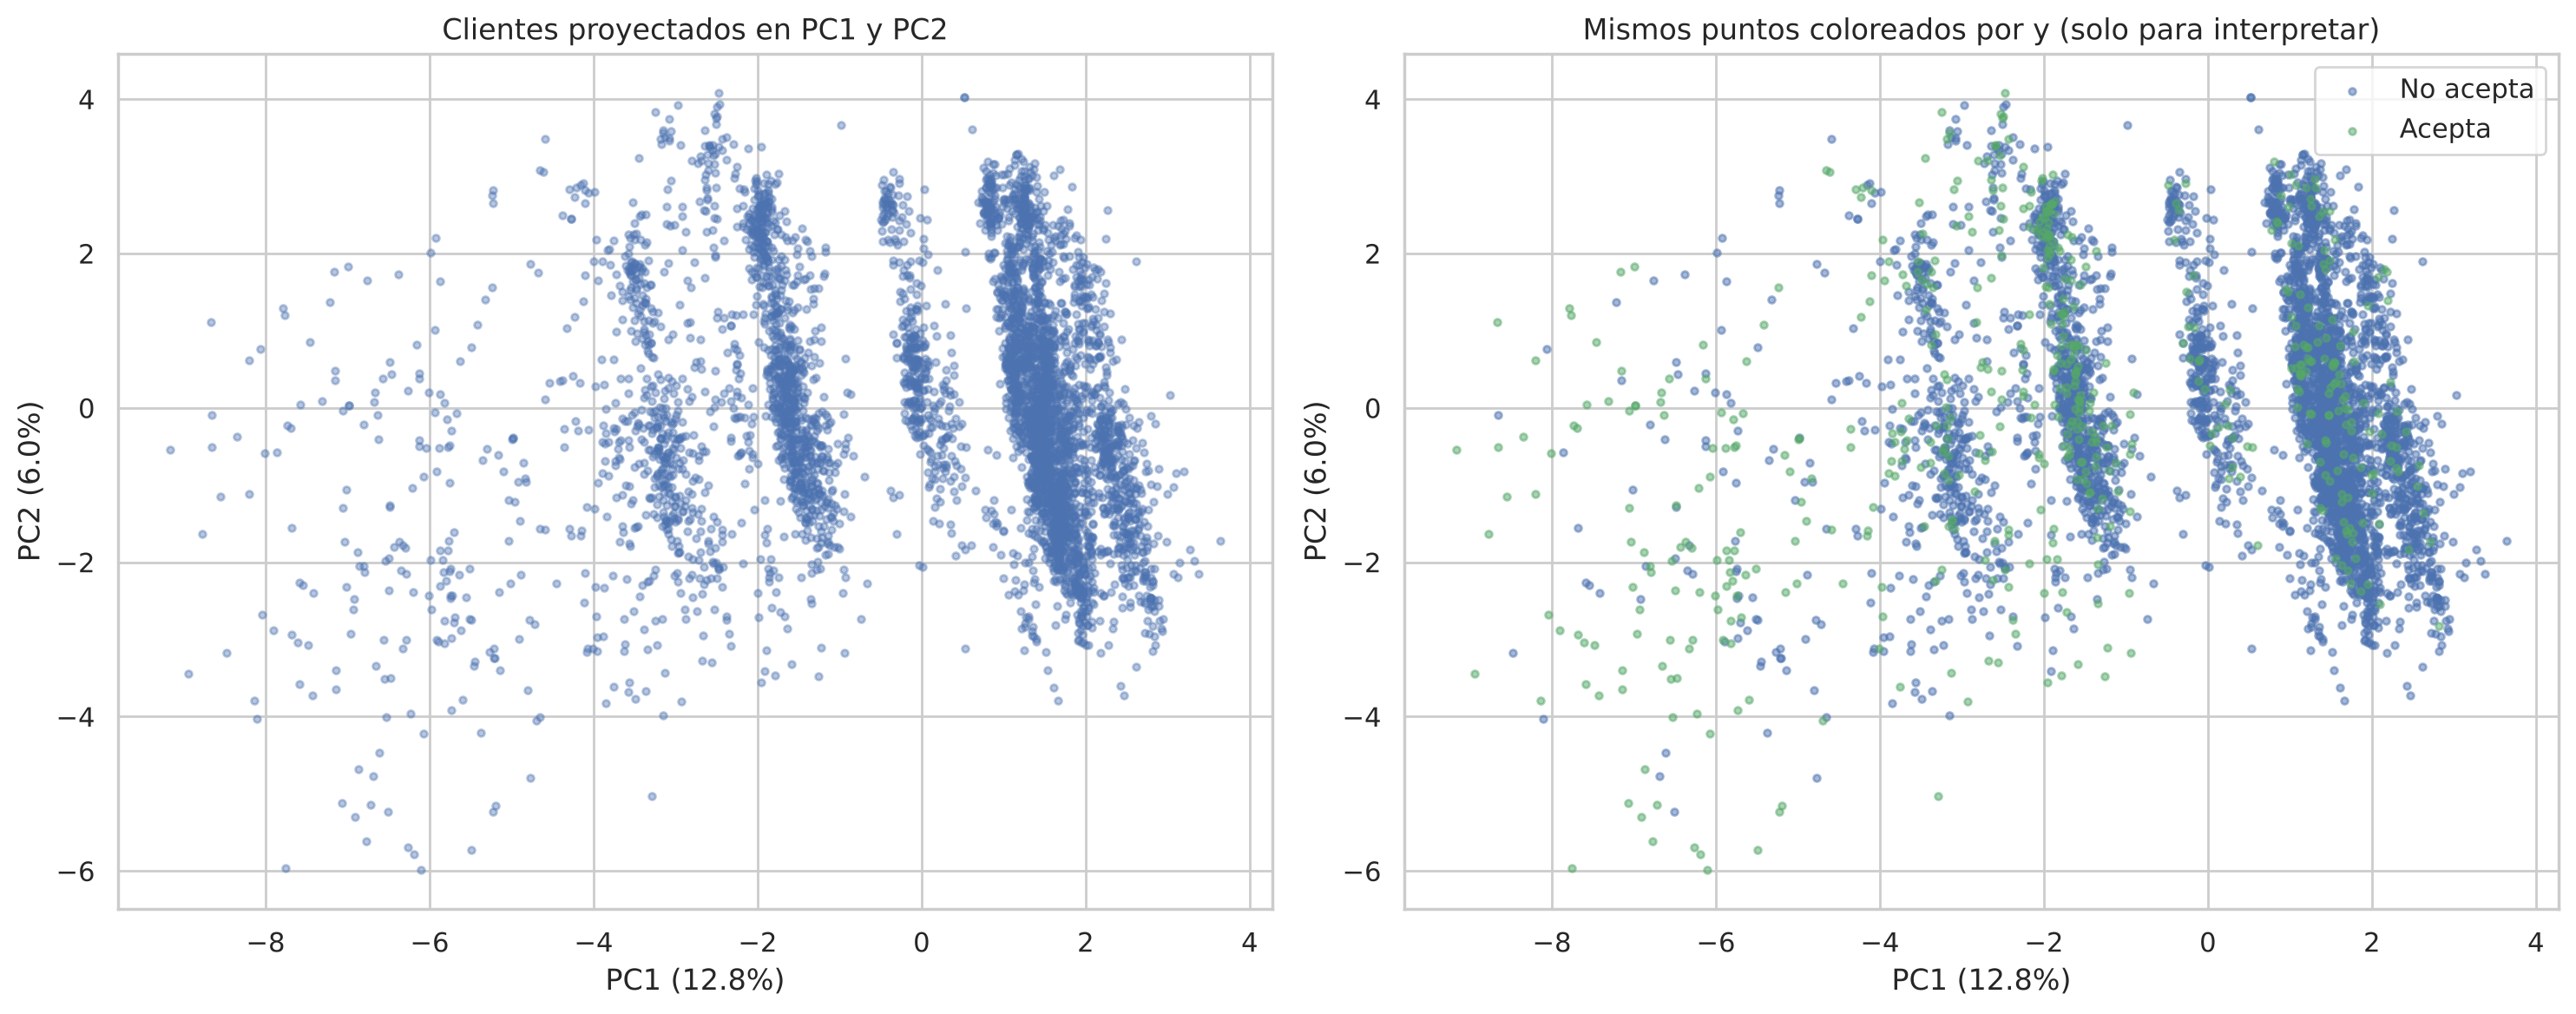

In [10]:
y = pd.read_csv("../data/processed/bank_clean.csv")["y"]
pcs = pd.DataFrame(X_pca[:, :3], columns=["PC1", "PC2", "PC3"])
pcs["y"] = y.map({0: "No acepta", 1: "Acepta"})

muestra = pcs.sample(5000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(muestra["PC1"], muestra["PC2"], s=8, alpha=0.4, color="#4C72B0")
axes[0].set_title("Clientes proyectados en PC1 y PC2")

for etiqueta, color in [("No acepta", "#4C72B0"), ("Acepta", "#55A868")]:
    d = muestra[muestra["y"] == etiqueta]
    axes[1].scatter(d["PC1"], d["PC2"], s=8, alpha=0.5, color=color, label=etiqueta)
axes[1].set_title("Mismos puntos coloreados por y (solo para interpretar)")
axes[1].legend()

for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.tight_layout()
plt.show()

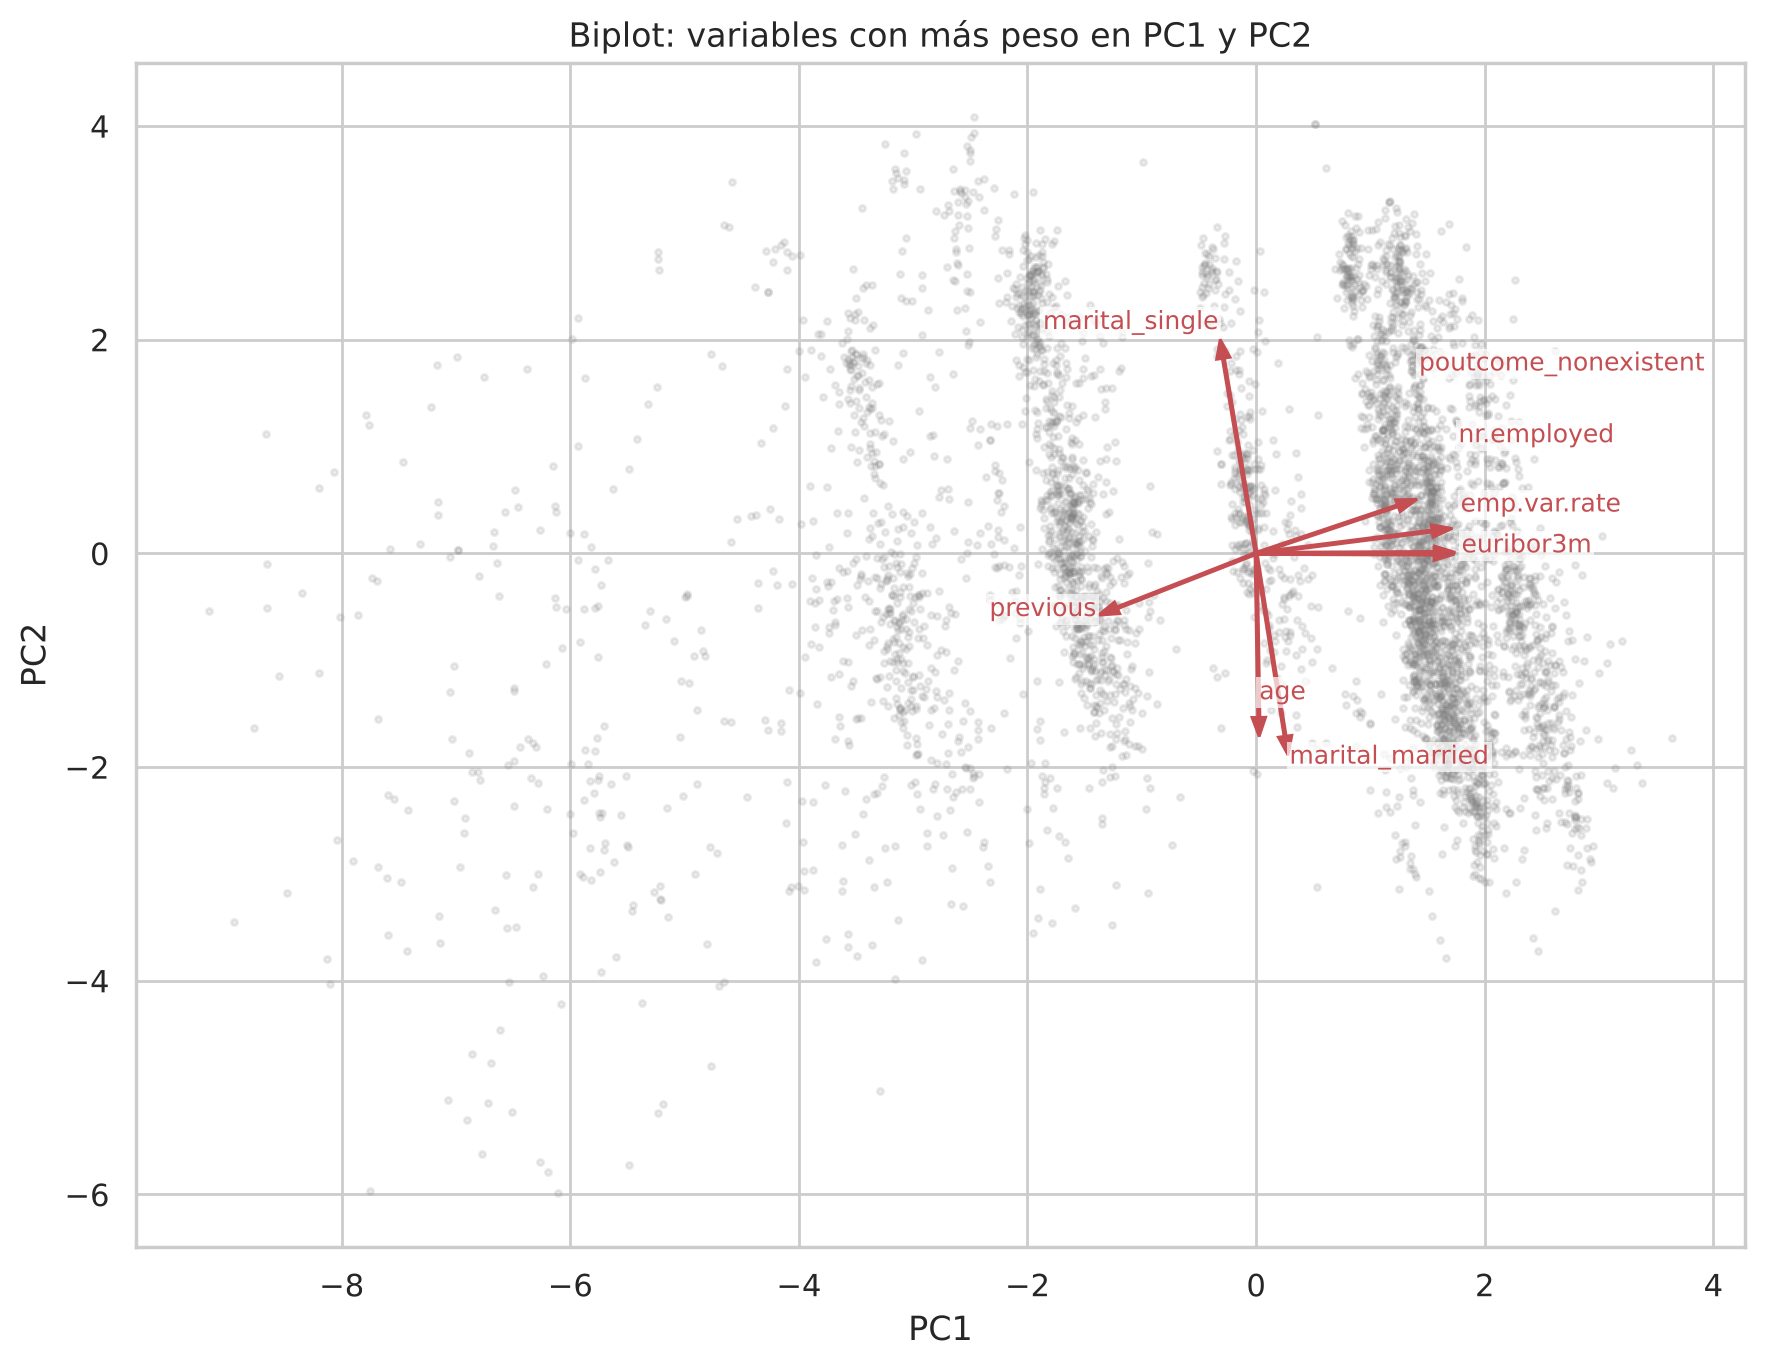

In [11]:
# Biplot: dirección de las variables con más peso en PC1 y PC2
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(muestra["PC1"], muestra["PC2"], s=5, alpha=0.15, color="gray")
fuertes = (cargas["PC1"] ** 2 + cargas["PC2"] ** 2).sort_values(ascending=False).head(8).index
escala = 4
usadas = []
for v in fuertes:
    x, yv = cargas.loc[v, "PC1"] * escala, cargas.loc[v, "PC2"] * escala
    ax.arrow(0, 0, x, yv, color="#C44E52", width=0.02, head_width=0.12)
    tx, ty = x * 1.15, yv * 1.15
    while any(abs(tx - ux) < 1.5 and abs(ty - uy) < 0.35 for ux, uy in usadas):
        ty += 0.4  # separar etiquetas que se enciman
    usadas.append((tx, ty))
    ax.text(tx, ty, v, color="#C44E52", fontsize=9, ha="left" if x > 0 else "right",
            bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=1))
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Biplot: variables con más peso en PC1 y PC2")
plt.tight_layout()
plt.show()

## 8. Relación de los componentes con la conversión

Para interpretar, se divide PC1 y PC2 en 5 partes iguales (quintiles) y se calcula el porcentaje de clientes que aceptan en cada parte.

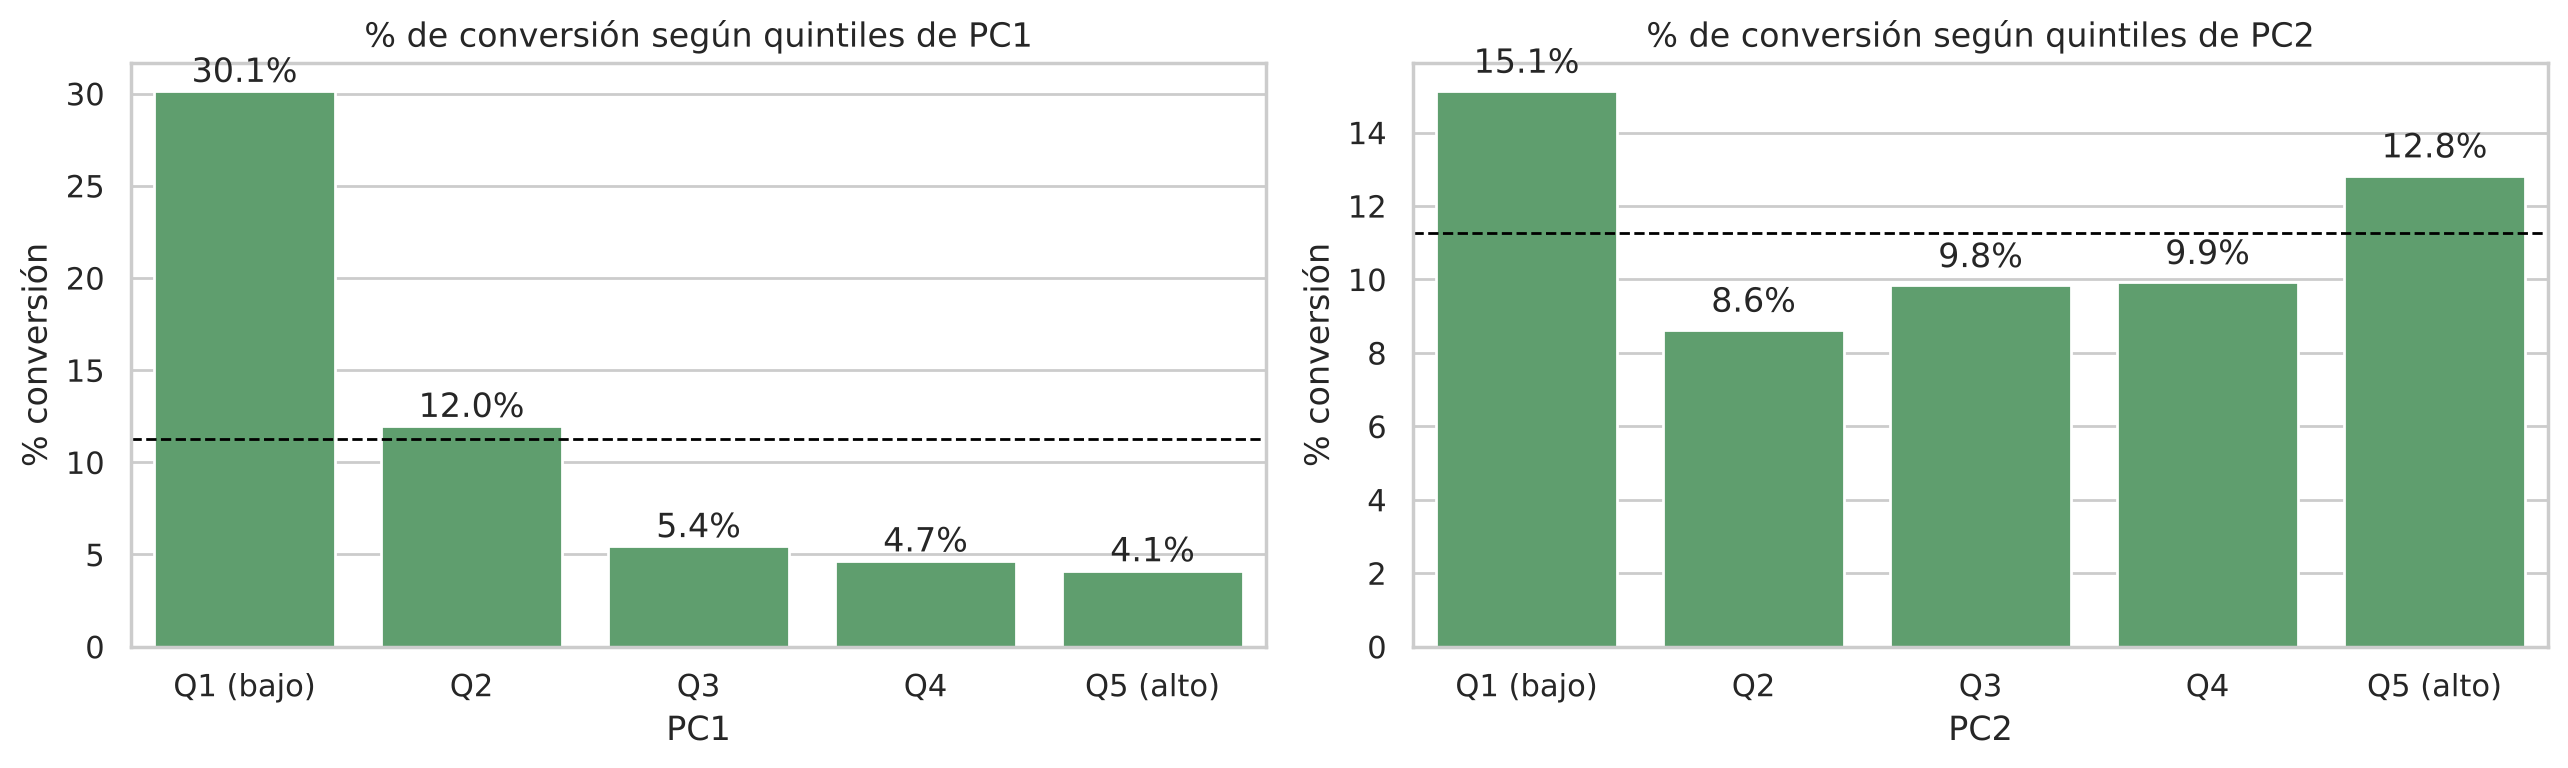

In [12]:
pcs["y_bin"] = y.values
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    pcs[f"{pc}_q"] = pd.qcut(pcs[pc], 5, labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"])
    tasa = pcs.groupby(f"{pc}_q", observed=True)["y_bin"].mean() * 100
    sns.barplot(x=tasa.index, y=tasa.values, ax=ax, color="#55A868")
    for i, v in enumerate(tasa.values):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
    ax.axhline(y.mean() * 100, ls="--", color="black", lw=1)
    ax.set_title(f"% de conversión según quintiles de {pc}")
    ax.set_xlabel(pc)
    ax.set_ylabel("% conversión")
plt.tight_layout()
plt.show()

## 9. ¿PCA ayuda a Naive Bayes?

Los componentes de PCA no están correlacionados entre sí, y eso es justamente lo que supone Naive Bayes. Por eso se prueba entrenar GaussianNB con los componentes en lugar de las variables originales.

Para hacerlo bien se usa la misma división train/test del notebook 03 y un `Pipeline` (escalado → PCA → Naive Bayes), así PCA solo aprende de los datos de entrenamiento.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score

df_clean = pd.read_csv("../data/processed/bank_clean.csv")
Xc, yc = df_clean.drop(columns=["y"]), df_clean["y"]
X_tr, X_te, y_tr, y_te = train_test_split(Xc, yc, test_size=0.2, stratify=yc, random_state=RANDOM_STATE)

filas = []
for k in [2, 5, 10, k_kaiser, k_80, k_90, Xc.shape[1]]:
    if k == Xc.shape[1]:
        pipe = Pipeline([("sc", StandardScaler()), ("nb", GaussianNB())])
        nombre = f"Sin PCA ({k} variables)"
    else:
        pipe = Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=k, random_state=RANDOM_STATE)), ("nb", GaussianNB())])
        nombre = f"PCA {k} componentes"
    pipe.fit(X_tr, y_tr)
    pred, proba = pipe.predict(X_te), pipe.predict_proba(X_te)[:, 1]
    filas.append({"configuración": nombre, "precision": precision_score(y_te, pred),
                  "recall": recall_score(y_te, pred), "f1": f1_score(y_te, pred),
                  "roc_auc": roc_auc_score(y_te, proba)})

comp_nb = pd.DataFrame(filas).drop_duplicates("configuración").set_index("configuración").round(4)
comp_nb

,precision,recall,f1,roc_auc
configuración,,,,
PCA 2 componentes,0.5707,0.2522,0.3498,0.7571
PCA 5 componentes,0.5589,0.2403,0.3361,0.7354
PCA 10 componentes,0.5037,0.2953,0.3723,0.7452
PCA 21 componentes,0.3316,0.4138,0.3682,0.7159
PCA 22 componentes,0.3372,0.4073,0.3690,0.7138
PCA 27 componentes,0.3211,0.4235,0.3652,0.7034
Sin PCA (41 variables),0.4278,0.4407,0.4342,0.7777


## 10. Guardar resultados para la comparación final

In [14]:
resultados_pca = {
    "modelo": "PCA",
    "variables_originales": int(X.shape[1]),
    "componentes_80": k_80,
    "componentes_90": k_90,
    "componentes_kaiser": k_kaiser,
    "componentes_elegidos": K,
    "varianza_conservada_%": round(float(pca.explained_variance_ratio_.sum() * 100), 2),
    "varianza_PC1_%": round(float(var_exp[0] * 100), 2),
    "varianza_PC2_%": round(float(var_exp[1] * 100), 2),
    "naive_bayes_con_pca": comp_nb.reset_index().to_dict(orient="records"),
}
with open("../data/processed/resultados_pca.json", "w") as f:
    json.dump(resultados_pca, f, indent=2, ensure_ascii=False)
{k: v for k, v in resultados_pca.items() if k != "naive_bayes_con_pca"}

{'modelo': 'PCA',
 'variables_originales': 41,
 'componentes_80': 22,
 'componentes_90': 27,
 'componentes_kaiser': 21,
 'componentes_elegidos': 22,
 'varianza_conservada_%': 80.52,
 'varianza_PC1_%': 12.81,
 'varianza_PC2_%': 5.96}

## 11. Interpretación de resultados

**Sobre la reducción de dimensiones:**

1. Con **22 componentes se conserva el 80,5% de la varianza** y se pasa de 41 a 22 variables (46% menos). El criterio de Kaiser da un resultado muy parecido (21 componentes, 78,1%).
2. La varianza está bastante repartida: PC1 explica 12,8% y desde PC6 cada componente explica menos de 4%. Esto pasa porque el dataset tiene muchas variables binarias del One-Hot Encoding que casi no se relacionan entre sí. PCA funciona mejor cuando hay muchas variables continuas correlacionadas, que en este dataset son pocas (sobre todo las económicas).
3. Se comprobó que los componentes no están correlacionados entre sí (correlación máxima = 0), que es justamente lo que busca PCA.

**Qué representa cada componente (según las cargas):**

4. **PC1 (12,8%), "contexto económico e historial":** tiene cargas altas y positivas en `euribor3m`, `emp.var.rate` y `nr.employed`, y negativa en `previous`. Es el componente que resume a las tres variables económicas muy correlacionadas que se vieron en el EDA.
5. **PC2 (6,0%), "perfil personal":** separa a los clientes solteros, jóvenes y con más estudios (valores positivos) de los casados, mayores y jubilados (valores negativos).
6. **PC3 (5,4%), "contactos anteriores":** combina `contactado_antes` y `poutcome_success` (positivo) contra las llamadas en mayo (negativo).
7. **PC4 y PC5, "canal y temporada":** tienen que ver con el tipo de contacto (`contact_cellular`) y los meses de la campaña (agosto, junio, julio, mayo).

**Relación con la conversión (usando `y` solo para interpretar):**

8. **PC1 es el componente más relacionado con la respuesta del cliente.** En el quintil más bajo de PC1 acepta el **30,1%**, y en el más alto solo el **4,1%**. Es decir, cuando las tasas económicas son bajas y el cliente ya fue contactado antes, la probabilidad de aceptar es mucho mayor. En el gráfico de dispersión se ve que los puntos verdes (aceptan) se concentran a la izquierda.
9. **PC2 tiene forma de "U":** los dos extremos tienen más conversión que el centro (15,1% en los mayores/jubilados y 12,8% en los jóvenes/solteros). Esto coincide con el EDA, donde jubilados y estudiantes eran los grupos que más aceptaban.
10. En el gráfico de PC1 vs PC2 se ven "franjas" verticales. **No son grupos formados por PCA** (PCA no agrupa), sino clientes que fueron llamados en el mismo periodo, porque las variables económicas toman pocos valores distintos (uno por mes de campaña).

**¿PCA ayuda a Naive Bayes?**

11. Aunque los componentes cumplen el supuesto de independencia de Naive Bayes, el modelo **no mejoró**: con 22 componentes el F1 bajó de 0,434 a 0,369 y el AUC de 0,778 a 0,714. Esto pasa porque PCA busca las direcciones con más varianza, no las que mejor separan a los que aceptan de los que no, y en esa reducción se pierde parte de la información útil para clasificar.
12. Algo interesante es que con solo **2 componentes** el AUC llega a 0,757, muy cerca del modelo con las 41 variables. Esto confirma que PC1 y PC2 guardan gran parte de la información importante.

**Limitaciones:**

13. PCA solo encuentra relaciones lineales entre variables.
14. Los componentes son más difíciles de explicar que las variables originales, porque cada uno mezcla varias variables.
15. Aplicar PCA sobre variables binarias es válido, pero no es lo ideal porque esas variables no tienen una varianza continua.
